In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import datetime as dt
import plotly.express as px
import numpy as np

In [2]:
#df1 - sun earth tools
df1 = pd.read_excel(r"C:\Users\abcal\dados_dt\set\set_20_3_24.xlsx")
#df2 - blender
df2 = pd.read_csv(r"C:\Users\abcal\dados_dt\bd\bd_20_3_24.csv")
#df3 - algoritmo incidência
df3 = pd.read_csv(r"C:\Users\abcal\dados_dt\alg_inc\20_3_24.txt", sep = ";")

#df4 - radiação
df4 = pd.read_csv(r"C:\Users\abcal\dados_dt\rad\rad_20_3_24.csv",sep = ';')

df4["Radiacao_Avg"] = df4["Radiacao_Avg"].str.replace(",", ".")
df4["Radiacao_Avg"] = df4["Radiacao_Avg"].astype(float)

In [3]:
def cortar_extremos_negativos(df):
    # máscara: True para linhas sem valores negativos
    mask = (df.select_dtypes(include=['number']) >= 0).all(axis=1)
    
    # índice da primeira e última linha válida
    first_valid = mask.idxmax()
    last_valid = mask[::-1].idxmax()
    
    # recorte do dataframe
    return df.loc[first_valid:last_valid]

df1 = cortar_extremos_negativos(df1)
df2 = cortar_extremos_negativos(df2)

In [4]:
#Plots de Elevação e Azimute (individuais)

#Elevação solar no blender
fig = px.line(df2, x ='Hora Solar', y = "Elevação (°)", title="Elevação solar - Blender (20/03/2024)")
fig.show()

#Verificando o comportamento da elevação solar no SunEarthTools.com
fig = px.line(df1, x ='Hora', y = "Elevacao", title="Elevação solar - SunEarthTools.com (20/03/2024)")
fig.show()

#Verificando o comportamento da elevação solar no Blender

fig = px.line(df2, x ='Hora Solar', y = "Azimute (°)", title="Azimute Solar - Blender (20/03/2024)")
fig.show()

#Verificando o comportamento da azimute solar no SunEarthTools.com

fig = px.line(df1, x ='Hora', y = "Azimute", title="Azimute solar - SunEarthTools.com (20/03/2024)")
fig.show()

In [5]:
#Ângulo de Incidência no Blender
fig = px.line(df2, x ='Hora Solar', y = "Ângulo de Incidência (°)", title="Ângulo de Incidência - Blender (20/03/2024)")
fig.show()

#Ângulo de Incidência validado no algoritmo 
fig = px.line(df3, x ='Tempo (HH:mm)', y ='incidência fixo', title="Ângulo de Incidência - Algoritmo Validado (20/03/2024)")
fig.show()


In [6]:
#Radiação
fig = px.line(df4, x ='Hora', y = "Radiacao_Avg", title="Radiação (20/03/2024)")
fig.show()

In [7]:
#Limpar nomes das colunas
df1.columns = df1.columns.str.strip()
df2.columns = df2.columns.str.strip()
df3.columns = df3.columns.str.strip()
df4.columns = df4.columns.str.strip()

#Convertendo horários para datetime
df1['Hora'] = pd.to_datetime(df1['Hora'], errors='coerce')
df2['Hora Solar'] = pd.to_datetime(df2['Hora Solar'], errors='coerce')
df3['Tempo (HH:mm)'] = pd.to_datetime(df3['Tempo (HH:mm)'], errors='coerce')
df4['Hora'] = pd.to_datetime(df4['Hora'], errors='coerce')

#Ordenando valores pelo tempo
df1 = df1.sort_values('Hora')
df2 = df2.sort_values('Hora Solar')
df3 = df3.sort_values('Tempo (HH:mm)')
df4 = df4.sort_values('Hora')

C:\Users\abcal\AppData\Local\Temp\ipykernel_24016\4160696207.py:8: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

C:\Users\abcal\AppData\Local\Temp\ipykernel_24016\4160696207.py:9: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

C:\Users\abcal\AppData\Local\Temp\ipykernel_24016\4160696207.py:10: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.

C:\Users\abcal\AppData\Local\Temp\ipykernel_24016\4160696207.py:11: UserWarning:

Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please speci

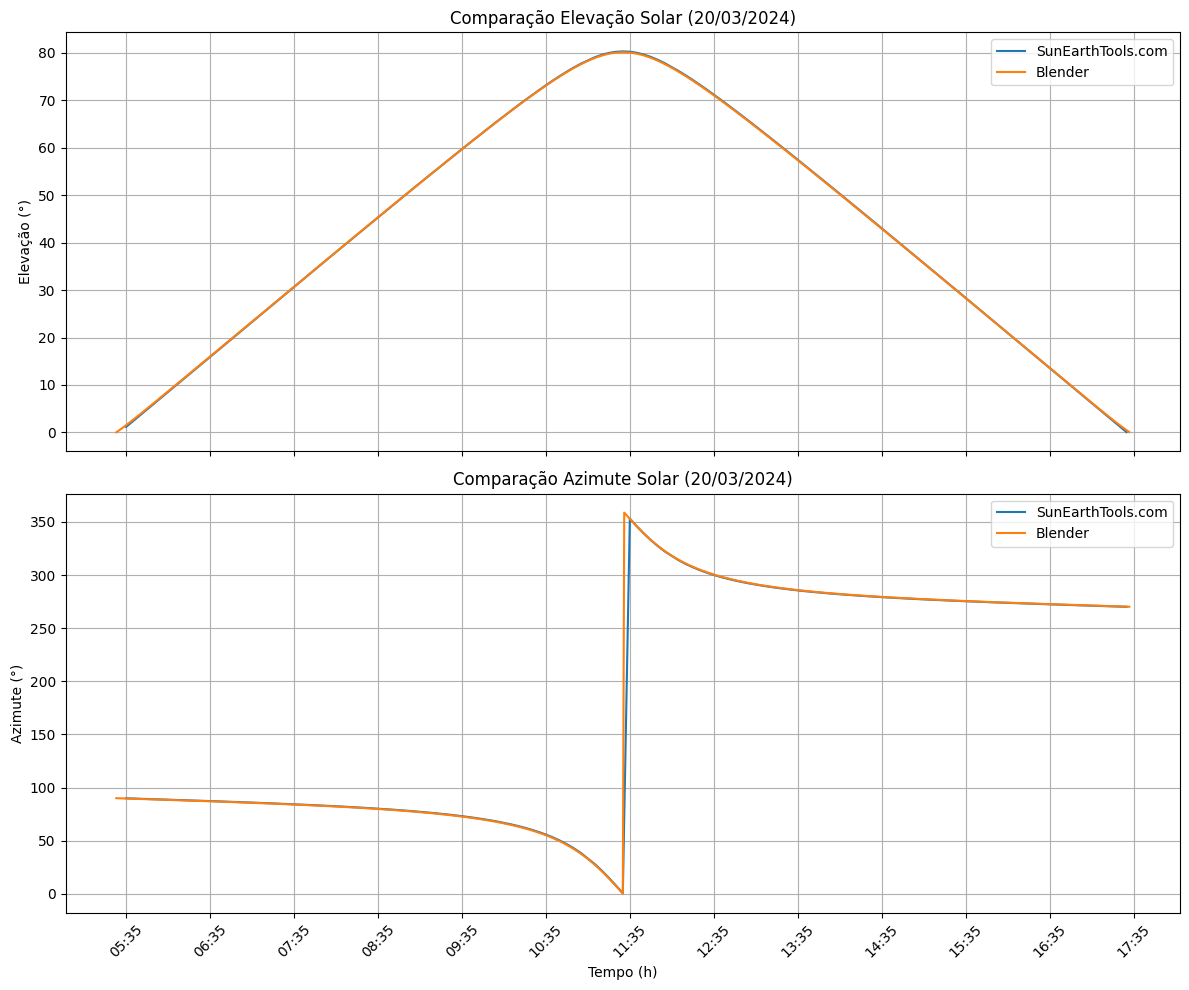

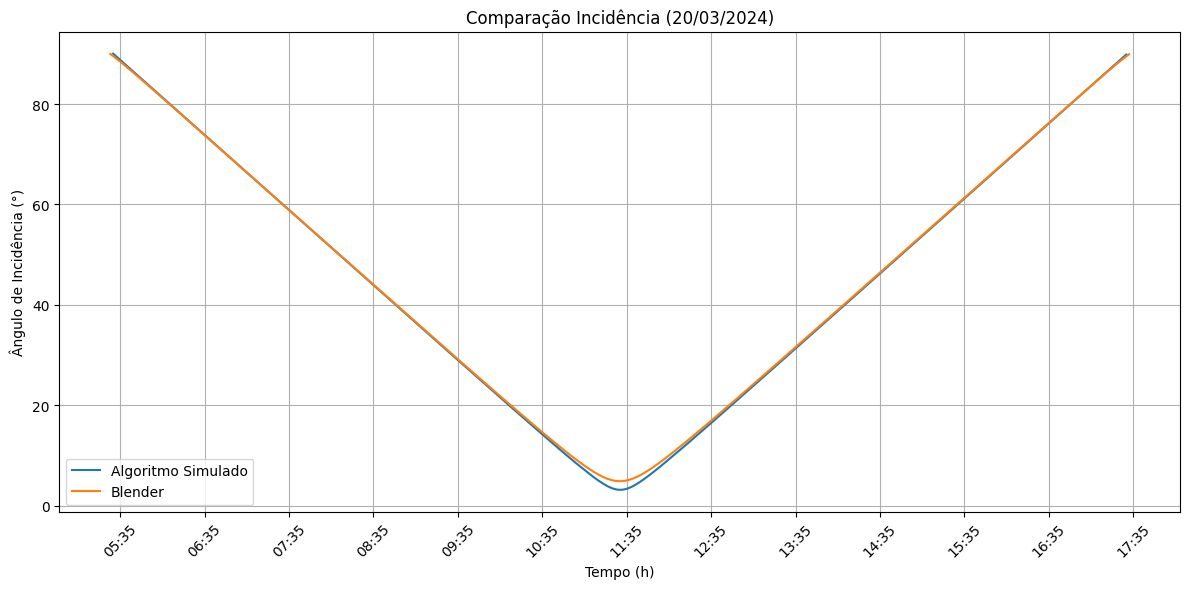

In [8]:
#Comparação 1 - Elevação e Azimute (SunEarthTools.com x Blender)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12,10), sharex=True)

#Elevação em graus
ax1.plot(df1['Hora'], df1['Elevacao'], label='SunEarthTools.com')
ax1.plot(df2['Hora Solar'], df2['Elevação (°)'], label='Blender')

ax1.set_ylabel('Elevação (°)')
ax1.set_title('Comparação Elevação Solar (20/03/2024)')
ax1.legend()
ax1.grid(True)

#Azimute em graus
ax2.plot(df1['Hora'], df1['Azimute'], label='SunEarthTools.com')
ax2.plot(df2['Hora Solar'], df2['Azimute (°)'], label='Blender')

ax2.set_ylabel('Azimute (°)')
ax2.set_xlabel('Tempo (h)')
ax2.set_title('Comparação Azimute Solar (20/03/2024)')
ax2.legend()
ax2.grid(True)

#Format o eixo de tempo
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax2.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


#Comparação 2 - Ângulo de Incidência (Algoritmo x Blender)
fig, ax = plt.subplots(figsize=(12,6))

#Ângulo de Incidência em graus
ax.plot(df3['Tempo (HH:mm)'], df3['incidência fixo'], label='Algoritmo Simulado')
ax.plot(df2['Hora Solar'], df2['Ângulo de Incidência (°)'], label='Blender')


ax.set_ylabel('Ângulo de Incidência (°)')
ax.set_xlabel('Tempo (h)')
ax.set_title('Comparação Incidência (20/03/2024)')

ax.legend()
ax.grid(True)

#Format o eixo de tempo
ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [9]:
#juntar dataframes com base no tempo

df12 = pd.merge(df2, df1, left_on='Hora Solar', right_on='Hora', how='inner')

df23 = pd.merge(df2, df3, left_on='Hora Solar', right_on='Tempo (HH:mm)', how='inner')

In [10]:
#cálculo do erro relativo em graus - (medido-real/real)
df12 = df12[df12['Elevacao'] > 5] #filtro 
df12['erro elevação'] = (abs(df12['Elevação (°)'] - df12['Elevacao'])/df12['Elevacao'])
df12['erro azimute'] = (abs(df12['Azimute (°)'] - df12['Azimute'])/df12['Azimute'])
df23['erro incidência'] = (abs(df23['Ângulo de Incidência (°)'] - df23['incidência fixo'])/ df23['incidência fixo'])

print(f"Erro médio elevação: {np.mean(df12['erro elevação']):.4f} +- {np.std(df12['erro elevação']):.4f}")
print(f"Erro médio azimute: {np.mean(df12['erro azimute']):.4f} +- {np.std(df12['erro azimute']):.4f}")
print(f"Erro médio incidência: {np.mean(df23['erro incidência']):.4f} +- {np.std(df23['erro incidência']):.4f}")

Erro médio elevação: 0.0020 +- 0.0030
Erro médio azimute: 0.0084 +- 0.0494
Erro médio incidência: 0.0349 +- 0.0972


In [11]:
rmse_el = np.sqrt(np.mean(df12['erro elevação']**2))
rmse_az = np.sqrt(np.mean(df12['erro azimute']**2))
rmse_inc = np.sqrt(np.mean(df23['erro incidência']**2))

print(f"RMSE Elevação: {rmse_el:.4f}")
print(f"RMSE Azimute: {rmse_az:.4f}")
print(f"RMSE Incidência: {rmse_inc:.4f}")

RMSE Elevação: 0.0036
RMSE Azimute: 0.0501
RMSE Incidência: 0.1032


In [12]:
df12.to_excel(r"C:\Users\abcal\dados_dt\erros\errosea_20_3_24.xlsx", index=False)
df23.to_excel(r"C:\Users\abcal\dados_dt\erros\errosi_20_3_24.xlsx", index=False)

In [13]:
print(len(df1))
print(len(df2))
print(len(df3))
#número de amostras
print(len(df12),len(df23))

144
725
721
123 601


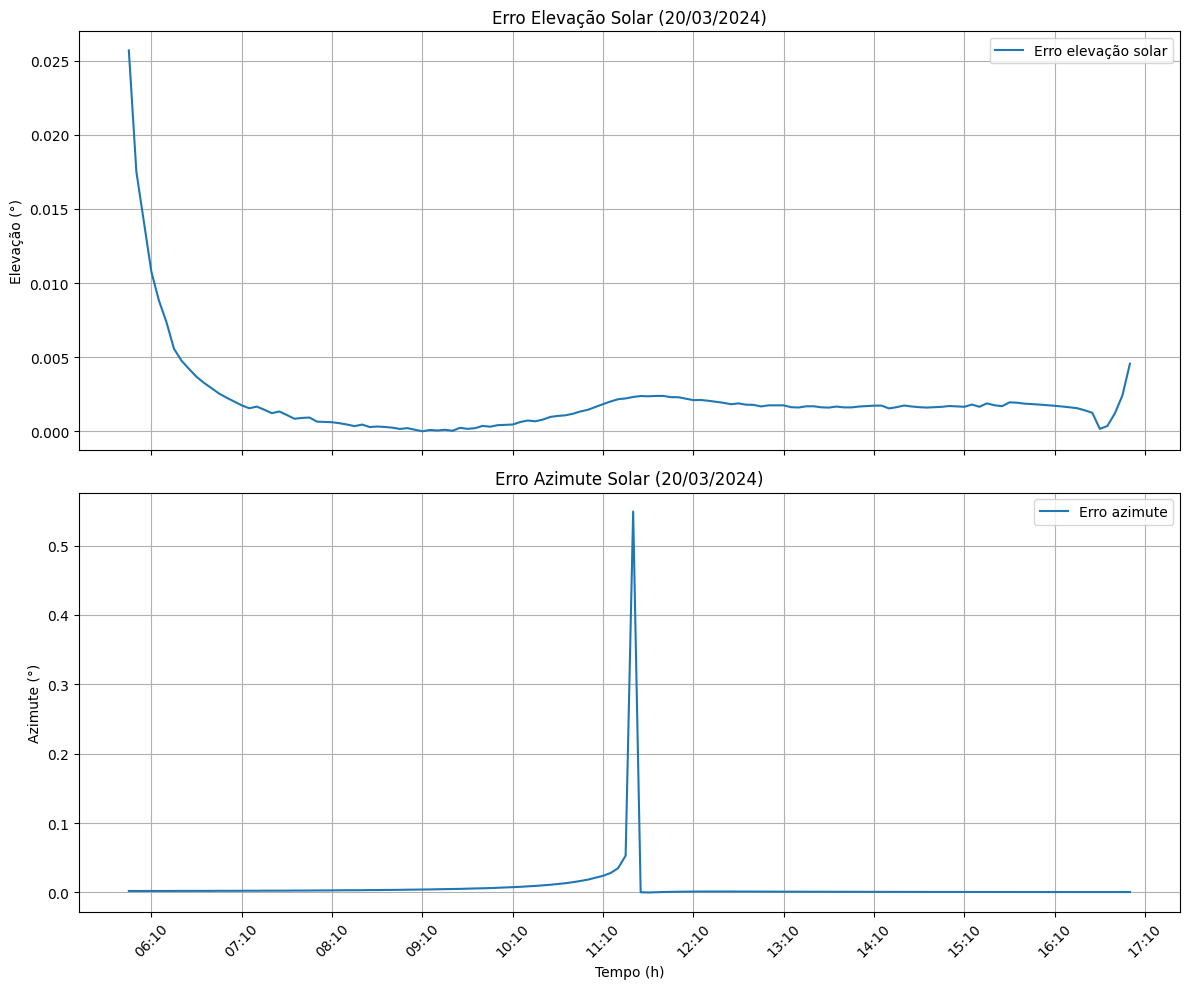

In [14]:
#Visualização dos erros
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12,10), sharex=True)

#Elevação em graus
ax1.plot(df12['Hora Solar'], df12['erro elevação'], label='Erro elevação solar')

ax1.set_ylabel('Elevação (°)')
ax1.set_title('Erro Elevação Solar (20/03/2024)')
ax1.legend()
ax1.grid(True)

#Azimute em graus
ax2.plot(df12['Hora Solar'], df12['erro azimute'], label='Erro azimute')

ax2.set_ylabel('Azimute (°)')
ax2.set_xlabel('Tempo (h)')
ax2.set_title('Erro Azimute Solar (20/03/2024)')
ax2.legend()
ax2.grid(True)

#Format o eixo de tempo
ax2.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax2.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

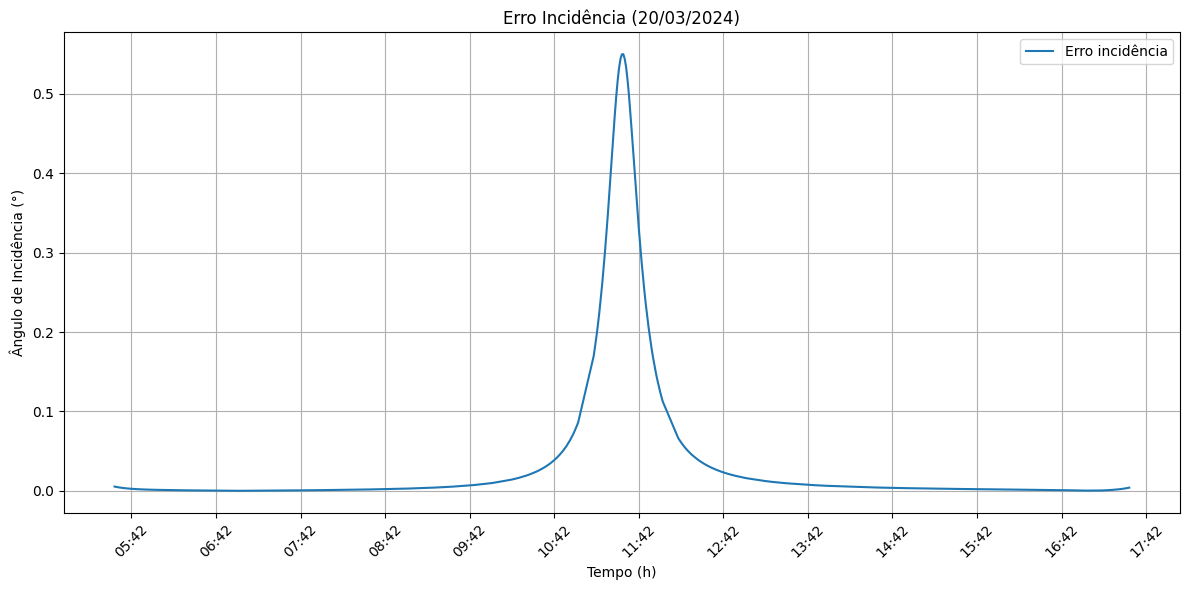

In [15]:
#Comparação 2 - Ângulo de Incidência (Algoritmo x Blender)
fig, ax = plt.subplots(figsize=(12,6))

#Ângulo de Incidência em graus
ax.plot(df23['Hora Solar'], df23['erro incidência'], label='Erro incidência')


ax.set_ylabel('Ângulo de Incidência (°)')
ax.set_xlabel('Tempo (h)')
ax.set_title('Erro Incidência (20/03/2024)')

ax.legend()
ax.grid(True)

ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

C:\Users\abcal\AppData\Local\Temp\ipykernel_24016\2960259125.py:28: UserWarning:

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.



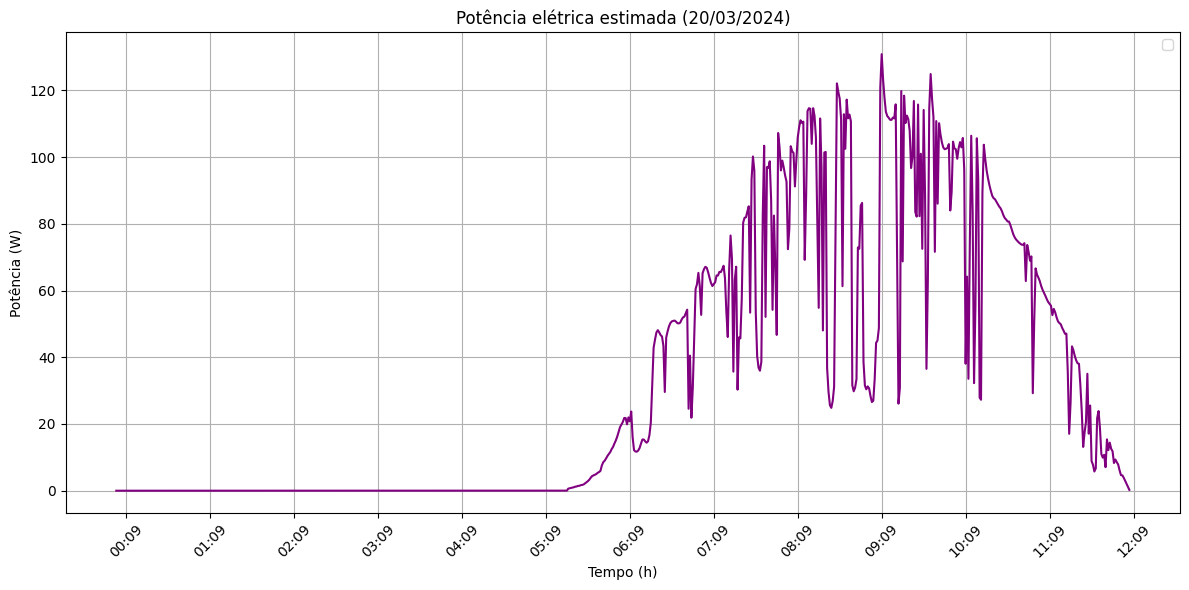

In [16]:
#Cálculo da Potência Elétrica

#Dados do painel
#Modelo - JKM270PP-60
#Dimensões - 1650 mm x 992 mm x 40 mm 
#Eficiência - 16,50%

a = 60*(0.156*0.156)
ef = 0.165

#Para que a potência fique positiva
w = np.radians(df2["Ângulo de Incidência (°)"] )

#Potência = radiação*área*eficiência*cos(âng de incidência)
df5 = pd.DataFrame()
df5["Potencia (W)"] = (df4["Radiacao_Avg"] *a *ef *np.cos(w))

#Plot
fig, ax = plt.subplots(figsize=(12,6))

ax.plot(df4["Hora"], df5["Potencia (W)"], color="purple")

ax.set_title("Potência elétrica estimada (20/03/2024)")
ax.set_ylabel("Potência (W)")
ax.set_xlabel("Tempo (h)")

ax.grid(True)
ax.legend()

ax.xaxis.set_major_formatter(mdates.DateFormatter('%H:%M'))
ax.xaxis.set_major_locator(mdates.MinuteLocator(interval=60))

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [17]:
df5["Energia (Wh)"] = df5["Potencia (W)"]*19 / 60

energia_total = df5["Energia (Wh)"].sum()

print("Energia total gerada no dia:",round(energia_total, 2), "Wh")

Energia total gerada no dia: 7445.44 Wh
